# Customer Cohort Retention & Lifetime Value Analysis

**Question:** Which customers and acquisition cohorts are worth the most to this retailer, and how quickly are they lost?

**Data:** [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) (UCI Machine Learning Repository, CC BY 4.0). Every transaction for a UK-based online gift retailer from December 2009 to December 2011, about 1.07 million line items. Many of its customers are wholesalers.

**Contents**
1. Data loading
2. Data quality and cleaning
3. Cohort retention
4. RFM segmentation
5. Customer lifetime value by cohort
6. Findings and recommendations

In [16]:
%pip install pandas openpyxl pyarrow matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## 1. Data loading

The raw data is an Excel file with one sheet per year. Both sheets are combined and saved as a Parquet file so later runs load in seconds instead of minutes. `Invoice`, `StockCode`, and `Description` are converted to text because they contain a mix of numbers and letters (for example, cancellation invoices start with "C"), which Parquet can't store in a single column.

In [ ]:
import os
import pandas as pd

parquet_path = "../data/raw/online_retail_II.parquet"

if os.path.exists(parquet_path):
    df = pd.read_parquet(parquet_path)
else:
    sheets = pd.read_excel("../data/raw/online_retail_II.xlsx", sheet_name=None)
    df = pd.concat(sheets.values(), ignore_index=True)
    df["Invoice"] = df["Invoice"].astype(str)
    df["StockCode"] = df["StockCode"].astype(str)
    df["Description"] = df["Description"].astype("string")
    df.to_parquet(parquet_path, index=False)

## 2. Data quality and cleaning

First, a scan for the common problems: missing values, cancellations, zero or negative quantities and prices, and duplicate rows.

In [18]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

print("Cancellations:", df["Invoice"].str.startswith("C").sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Unique customers:", df["Customer ID"].nunique())
print("Exact duplicates:", df.duplicated().sum())

(1067371, 8)
Invoice                   str
StockCode                 str
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Cancellations: 19494
Quantity <= 0: 22950
Price <= 0: 6207
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Unique customers: 5942
Exact duplicates: 34335


**What the inspection shows**

| Issue | Rows | What it means |
|---|---|---|
| Missing Customer ID | 243,007 (~23%) | Can't be assigned to a cohort |
| Cancellations (invoice starts with "C") | 19,494 | Refunds; needed to calculate net revenue |
| Quantity ≤ 0 | 22,950 | Includes ~3,500 stock adjustments that aren't cancellations |
| Price ≤ 0 | 6,207 | Free items and accounting entries, not real sales |
| Exact duplicates | 34,335 | The same line item recorded twice |

The date range is 1 December 2009 to 9 December 2011. That creates two traps for cohort analysis:
- **December 2009 isn't a real acquisition cohort.** Because the data starts that month, every existing customer looks "new."
- **December 2011 has only 9 days of data,** so it would look like a drop in retention when it's just incomplete.

Some stock codes aren't products: postage, bank fees, manual adjustments, test entries. These are checked below so they can be excluded, because they don't reflect what customers actually buy.

In [19]:
# Stock codes that aren't the normal 5-digit product format (optionally with a letter suffix)
odd_codes = df[~df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")]
print(odd_codes["StockCode"].value_counts().head(30))

StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
gift_0001_10      16
CRUK              16
DCGS0076          15
TEST001           15
DCGS0003          14
gift_0001_50       8
gift_0001_40       7
DCGS0069           6
B                  6
DCGS0004           5
m                  5
gift_0001_80       4
DCGS0072           4
DCGS0066N          4
DCGS0068           3
Name: count, dtype: int64


In [20]:
check = df[df["StockCode"].str.startswith(("DCGS", "M", "PADS"))]
print(check.groupby("StockCode")["Description"].first().head(20))

StockCode
DCGS0003                  BOXED GLASS ASHTRAY
DCGS0004           HAYNES CAMPER SHOULDER BAG
DCGS0006                                 <NA>
DCGS0016                                 <NA>
DCGS0027                                 <NA>
DCGS0036                                 <NA>
DCGS0037                   KEY-RING CORKSCREW
DCGS0039                                 <NA>
DCGS0041     HAYNES MINI-COOPER PLAYING CARDS
DCGS0044              HANDZ-OFF CAR FRESHENER
DCGS0053                                 <NA>
DCGS0055                                 <NA>
DCGS0056                                 <NA>
DCGS0057                                 <NA>
DCGS0058                     MISO PRETTY  GUM
DCGS0059                                 <NA>
DCGS0060                                 <NA>
DCGS0062              ROAD-RAGE CAR FRESHENER
DCGS0066N             NAVY CUDDLES DOG HOODIE
DCGS0066P                                <NA>
Name: Description, dtype: string


In [21]:
clean = df.drop_duplicates().copy()
log = [("Raw rows", len(df)), ("After dropping exact duplicates", len(clean))]

# Keep real products: 5-digit codes (optional letter suffix) plus DCGS codes
is_product = (
    clean["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")
    | clean["StockCode"].str.startswith("DCGS")
)
clean = clean[is_product].copy()
log.append(("After dropping non-product codes", len(clean)))

clean["Revenue"] = clean["Quantity"] * clean["Price"]

# How much do we lose by dropping rows without a customer?
missing_id = clean["Customer ID"].isna()
print(f"Rows missing Customer ID: {missing_id.mean():.1%}")
print(f"Revenue on rows missing Customer ID: "
      f"{clean.loc[missing_id, 'Revenue'].sum() / clean['Revenue'].sum():.1%}")

clean = clean[~missing_id].copy()
clean["Customer ID"] = clean["Customer ID"].astype("int64")
log.append(("After dropping missing Customer ID", len(clean)))

# Split cancellations from purchases
is_cancel = clean["Invoice"].str.startswith("C")
cancellations = clean[is_cancel].copy()
purchases = clean[~is_cancel & (clean["Quantity"] > 0) & (clean["Price"] > 0)].copy()
log.append(("Purchase rows", len(purchases)))
log.append(("Cancellation rows", len(cancellations)))

for step, rows in log:
    print(f"{step:<40}{rows:>12,}")

Rows missing Customer ID: 22.7%
Revenue on rows missing Customer ID: 13.6%
Raw rows                                   1,067,371
After dropping exact duplicates            1,033,036
After dropping non-product codes           1,027,212
After dropping missing Customer ID           794,223
Purchase rows                                776,577
Cancellation rows                             17,586


**Cleaning rules applied**

1. **Removed exact duplicates** (34,335 rows): they double-count revenue.
2. **Kept only real product codes:** standard 5-digit codes plus `DCGS` codes, which the descriptions confirm are real products. This removed postage, fees, manual adjustments, and gift vouchers (5,824 rows).
3. **Removed rows with no Customer ID:** they can't be placed in a cohort. This is 22.7% of rows but only **13.6% of revenue**, because anonymous transactions are smaller than average. The analysis still covers the large majority of sales value.
4. **Separated cancellations from purchases.** Retention counts purchases only, but lifetime value is calculated *net* of refunds.

Result: **776,577 purchase rows** and **17,586 cancellation rows** across 5,852 customers.

## 3. Cohort retention

Each customer is assigned to a **cohort**, the month of their first purchase. The **cohort index** counts months since that first purchase (0 = the month they were acquired). Retention is the share of each cohort that makes a purchase in a given month after acquisition.

December 2011 is excluded as an activity month because it only has 9 days of data.

In [22]:
purchases["InvoiceMonth"] = purchases["InvoiceDate"].dt.to_period("M")

# Each customer's cohort = the month of their first purchase
purchases["CohortMonth"] = (
    purchases.groupby("Customer ID")["InvoiceMonth"].transform("min")
)

# Months since first purchase (0 = the month they were acquired)
purchases["CohortIndex"] = (
    (purchases["InvoiceMonth"].dt.year - purchases["CohortMonth"].dt.year) * 12
    + (purchases["InvoiceMonth"].dt.month - purchases["CohortMonth"].dt.month)
)

print(purchases[["Customer ID", "InvoiceMonth", "CohortMonth", "CohortIndex"]].head(10))
print("\nNew customers per cohort:")
print(purchases.groupby("CohortMonth")["Customer ID"].nunique())

   Customer ID InvoiceMonth CohortMonth  CohortIndex
0        13085      2009-12     2009-12            0
1        13085      2009-12     2009-12            0
2        13085      2009-12     2009-12            0
3        13085      2009-12     2009-12            0
4        13085      2009-12     2009-12            0
5        13085      2009-12     2009-12            0
6        13085      2009-12     2009-12            0
7        13085      2009-12     2009-12            0
8        13085      2009-12     2009-12            0
9        13085      2009-12     2009-12            0

New customers per cohort:
CohortMonth
2009-12    951
2010-01    368
2010-02    375
2010-03    441
2010-04    294
2010-05    255
2010-06    267
2010-07    185
2010-08    163
2010-09    239
2010-10    375
2010-11    326
2010-12     76
2011-01     72
2011-02    125
2011-03    179
2011-04    106
2011-05    111
2011-06    108
2011-07    101
2011-08    107
2011-09    188
2011-10    221
2011-11    191
2011-12     28
Fre

In [23]:
cutoff = pd.Period("2011-12", freq="M")
retention_data = purchases[purchases["InvoiceMonth"] < cutoff]

# Count active customers for each cohort in each month since acquisition
cohort_counts = (
    retention_data.groupby(["CohortMonth", "CohortIndex"])["Customer ID"]
    .nunique()
    .unstack()
)

# Divide each row by its month-0 size to get retention rates
cohort_sizes = cohort_counts[0]
retention = cohort_counts.divide(cohort_sizes, axis=0)

print(retention.round(2).iloc[:, :7])

CohortIndex    0     1     2     3     4     5     6
CohortMonth                                         
2009-12      1.0  0.35  0.33  0.42  0.38  0.36  0.38
2010-01      1.0  0.21  0.32  0.32  0.27  0.31  0.27
2010-02      1.0  0.23  0.23  0.29  0.25  0.20  0.19
2010-03      1.0  0.19  0.23  0.24  0.23  0.20  0.25
2010-04      1.0  0.19  0.19  0.16  0.18  0.22  0.28
2010-05      1.0  0.16  0.17  0.18  0.18  0.25  0.21
2010-06      1.0  0.18  0.19  0.21  0.23  0.28  0.13
2010-07      1.0  0.16  0.18  0.30  0.29  0.14  0.11
2010-08      1.0  0.20  0.29  0.33  0.17  0.12  0.10
2010-09      1.0  0.23  0.23  0.13  0.09  0.10  0.14
2010-10      1.0  0.26  0.15  0.13  0.09  0.08  0.13
2010-11      1.0  0.17  0.10  0.10  0.08  0.09  0.13
2010-12      1.0  0.09  0.05  0.09  0.12  0.07  0.05
2011-01      1.0  0.17  0.22  0.19  0.22  0.15  0.15
2011-02      1.0  0.16  0.16  0.18  0.22  0.16  0.16
2011-03      1.0  0.18  0.22  0.20  0.22  0.15  0.21
2011-04      1.0  0.25  0.20  0.20  0.18  0.24

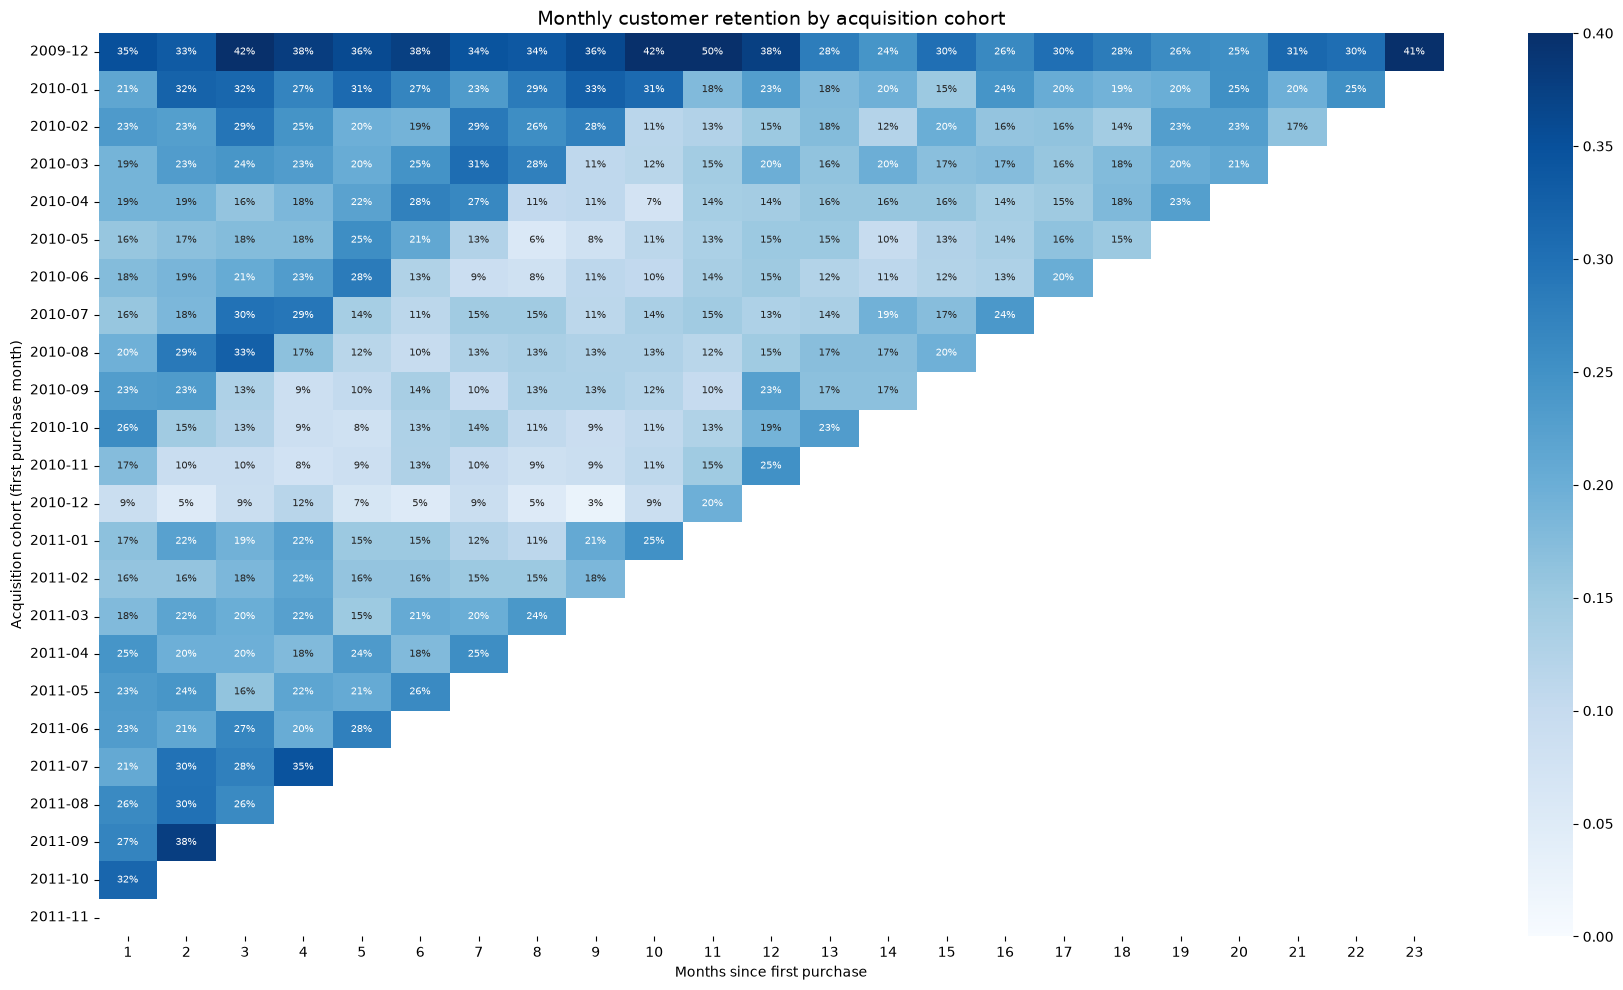

In [24]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../images", exist_ok=True)

fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(
    retention.drop(columns=0),
    annot=True,
    fmt=".0%",
    annot_kws={"size": 7},
    cmap="Blues",
    vmin=0,
    vmax=0.4,
    ax=ax,
)
ax.set_title("Monthly customer retention by acquisition cohort", fontsize=14)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Acquisition cohort (first purchase month)")
plt.tight_layout()
fig.savefig("../images/retention_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**What the retention heatmap shows**

- **A typical cohort keeps 16–26% of customers in month 1, then roughly holds that level.** Customers who come back once tend to keep coming back, which fits a business with many wholesale buyers.
- **December 2009 (top row) retains far better than any other cohort,** at 24–50%. That's the data start problem: it's the existing customer base, not new customers, so it's excluded from comparisons.
- **Holiday acquired cohorts retain worst.** The December 2010 cohort is the palest row in the chart, mostly at 3 - 12% retention through its first year, against roughly 15 - 25% for spring 2010 cohorts.
- **The diagonal bands are seasonality.** The darker cells running diagonally all fall in the same calendar months, October and November 2010 and again in November 2011. Every cohort, whatever its age, buys more in the run-up to the holidays. Retention here depends on the calendar as much as on how long someone has been a customer.

**Caveat:** Part of the holiday cohorts' weak retention is timing. Their early months fall in January through March, when every cohort buys less. A cleaner test would compare the 2010 and 2011 holiday cohorts at the same age, but the data doesn't run long enough.

## 4. RFM segmentation

RFM scores each customer on three behaviors:
- **Recency:** days since their last purchase (lower is better)
- **Frequency:** number of separate orders
- **Monetary:** total net revenue

"Today" for the analysis is the day after the last transaction in the data.

In [25]:
# "Today" for the analysis = the day after the last transaction in the data
snapshot = purchases["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = purchases.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)
rfm["Recency"] = (snapshot - rfm["LastPurchase"]).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]]

print(rfm.head())
print(rfm.describe().round(1))

             Recency  Frequency  Monetary
Customer ID                              
12346            326          3  77352.96
12347              2          8   4921.53
12348             75          5   1658.40
12349             19          3   3678.69
12350            310          1    294.40
       Recency  Frequency  Monetary
count   5852.0     5852.0    5852.0
mean     200.2        6.3    2916.7
std      208.5       12.7   14306.9
min        1.0        1.0       3.0
25%       25.0        1.0     339.6
50%       95.0        3.0     856.0
75%      379.0        7.0    2241.0
max      739.0      373.0  580987.0


Monetary value is heavily skewed. The mean (£2,917) is more than three times the median (£856), and the largest customer spent £580,987, which reflects a small group of high-volume wholesale buyers.

Customer 12346 stands out: £77,353 in purchases from only 3 orders, then no activity for 326 days. That pattern suggests a large cancelled order, which is checked below.

Monetary value is heavily skewed. The mean (£2,917) is more than three times the median (£856), and the largest customer spent £580,987, which reflects a small group of high-volume wholesale buyers.

Customer 12346 stands out: £77,353 in purchases from only 3 orders, then no activity for 326 days. That pattern suggests a large cancelled order, which is checked below.

In [26]:
print(cancellations.loc[cancellations["Customer ID"] == 12346, "Revenue"].sum())

-77183.6


In [27]:
net_cancel = cancellations.groupby("Customer ID")["Revenue"].sum()  # negative values
rfm["Monetary"] = rfm["Monetary"] + net_cancel.reindex(rfm.index, fill_value=0)

print("Customers with net Monetary <= 0:", (rfm["Monetary"] <= 0).sum())
print(rfm["Monetary"].describe().round(1))

Customers with net Monetary <= 0: 19
count      5852.0
mean       2795.6
std       13825.3
min       -1343.2
25%         330.9
50%         840.2
75%        2172.0
max      578408.6
Name: Monetary, dtype: float64


Customer 12346 cancelled £77,184 of their £77,353, so their real net spend is about £169. Without netting out cancellations, they would have scored as one of the most valuable customers in the dataset. **Monetary is therefore calculated net of cancellations.**

19 customers (0.3%) end up at zero or negative net revenue, most likely refunds on orders placed before the data starts. They're excluded from scoring.

**Scoring:** each customer gets a 1–5 score on R, F, and M using quintiles, so each score holds about 20% of customers. Scoring by rank rather than by fixed spending bands keeps the few very large wholesale customers from distorting the scale. More than a quarter of customers have exactly one order, so Frequency is ranked first to break ties. That means two customers with the same order count can receive different F scores, a standard trade-off in RFM.

In [28]:
rfm = rfm[rfm["Monetary"] > 0].copy()
print("Customers scored:", len(rfm))

# Recency: fewer days = better, so the labels run backwards
rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Frequency: many customers tie at 1 order, so rank first to break ties
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

print(rfm.head())
print(rfm[["R", "F", "M"]].apply(pd.Series.value_counts))

Customers scored: 5833
             Recency  Frequency  Monetary  R  F  M
Customer ID                                       
12346            326          3    169.36  2  3  1
12347              2          8   4921.53  5  4  5
12348             75          5   1658.40  3  4  4
12349             19          3   3654.54  5  3  5
12350            310          1    294.40  2  1  2
      R     F     M
1  1164  1167  1167
2  1167  1166  1166
3  1144  1167  1167
4  1172  1166  1166
5  1186  1167  1167


In [29]:
def rfm_segment(row):
    r, f = row["R"], row["F"]
    if r == 5 and f >= 4:
        return "Champions"
    elif r >= 3 and f >= 4:
        return "Loyal"
    elif r >= 4 and f >= 2:
        return "Potential Loyalists"
    elif r == 5 and f == 1:
        return "New Customers"
    elif r == 4 and f == 1:
        return "Promising"
    elif r == 3 and f == 3:
        return "Need Attention"
    elif r == 3 and f <= 2:
        return "About to Sleep"
    elif r <= 2 and f == 5:
        return "Can't Lose Them"
    elif r <= 2 and f >= 3:
        return "At Risk"
    else:
        return "Hibernating"

rfm["Segment"] = rfm.apply(rfm_segment, axis=1)

seg_summary = rfm.groupby("Segment").agg(
    Customers=("R", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    TotalRevenue=("Monetary", "sum"),
)
seg_summary["PctCustomers"] = seg_summary["Customers"] / seg_summary["Customers"].sum()
seg_summary["PctRevenue"] = seg_summary["TotalRevenue"] / seg_summary["TotalRevenue"].sum()
seg_summary = seg_summary.sort_values("TotalRevenue", ascending=False)

print(seg_summary.round(2))

                     Customers  AvgRecency  AvgFrequency  AvgMonetary  \
Segment                                                                 
Champions                  833        8.59         19.22     10302.48   
Loyal                     1142       66.39          9.78      3957.68   
At Risk                    753      370.50          3.92      1268.53   
Potential Loyalists        717       25.77          2.59       879.97   
Hibernating               1506      456.25          1.25       404.55   
Can't Lose Them             72      327.25         16.36      6648.12   
Need Attention             265      112.40          3.15      1250.04   
About to Sleep             375      106.41          1.37       523.36   
Promising                  116       39.02          1.00       340.92   
New Customers               54       10.67          1.00       348.30   

                     TotalRevenue  PctCustomers  PctRevenue  
Segment                                                      

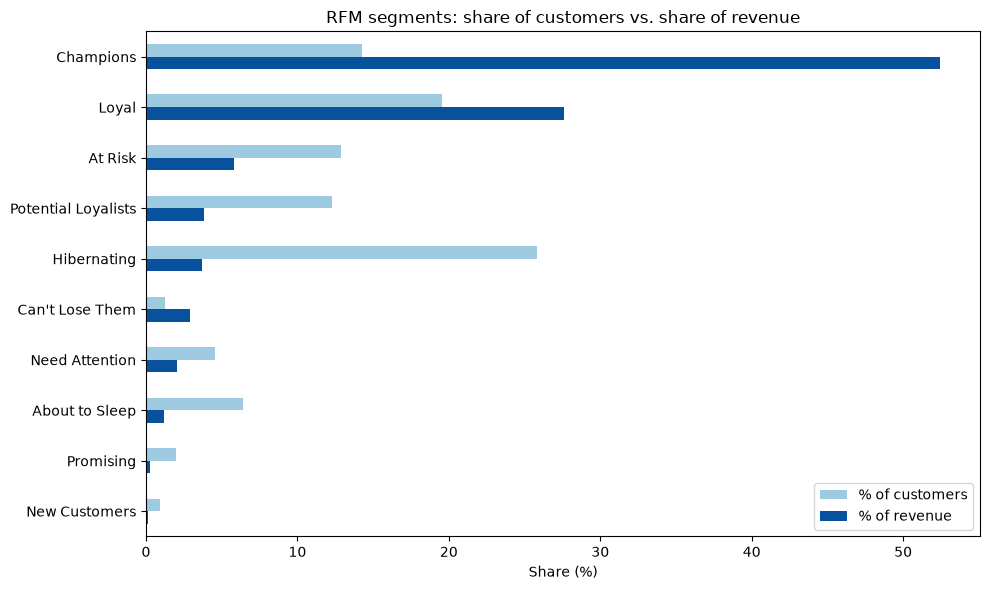

In [30]:
plot_df = seg_summary[["PctCustomers", "PctRevenue"]].mul(100)

ax = plot_df.plot(kind="barh", figsize=(10, 6), color=["#9ecae1", "#08519c"])
ax.invert_yaxis()
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.set_title("RFM segments: share of customers vs. share of revenue")
ax.legend(["% of customers", "% of revenue"])
plt.tight_layout()
plt.savefig("../images/rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

**What the segments show**

Segments are built from R and F scores (how recently and how often a customer buys), and Monetary is used to measure each segment's value.

- **Champions are 14% of customers and 52% of net revenue.** Champions and Loyal together are **34% of customers and 80% of revenue**, close to the classic 80/20 pattern.
- **Hibernating is the largest segment (26% of customers) but brings in only 4% of revenue.**
- **"Can't Lose Them" is the most actionable segment:** 72 customers averaging 16 orders and £6,648 each, who haven't bought in about 11 months. That's £479K of historical revenue that has gone quiet.
- **Potential Loyalists** (717 customers) bought recently but average only 2.6 orders. They're the main pool for growing the Loyal segment.

## 5. Customer lifetime value by cohort

Lifetime value (LTV) here is **cumulative net revenue per customer**, tracked by months since acquisition. Cancellations are subtracted in the month they occurred, so LTV reflects what customers actually kept. As with retention, December 2011 is excluded, and each cohort only shows the months it has actually reached.

In [31]:
cohort_lookup = purchases.groupby("Customer ID")["CohortMonth"].first()

canc = cancellations.copy()
canc["InvoiceMonth"] = canc["InvoiceDate"].dt.to_period("M")
canc["CohortMonth"] = canc["Customer ID"].map(cohort_lookup)
canc = canc.dropna(subset=["CohortMonth"])
canc["CohortIndex"] = (
    (canc["InvoiceMonth"].dt.year - canc["CohortMonth"].dt.year) * 12
    + (canc["InvoiceMonth"].dt.month - canc["CohortMonth"].dt.month)
)
canc = canc[canc["CohortIndex"] >= 0]

cols = ["Customer ID", "InvoiceMonth", "CohortMonth", "CohortIndex", "Revenue"]
net = pd.concat([purchases[cols], canc[cols]])
net = net[net["InvoiceMonth"] < cutoff]

print("Purchase revenue:", round(purchases.loc[purchases["InvoiceMonth"] < cutoff, "Revenue"].sum()))
print("Net revenue:     ", round(net["Revenue"].sum()))

Purchase revenue: 16556340
Net revenue:      16025194


In [32]:
monthly_rev = (
    net.groupby(["CohortMonth", "CohortIndex"])["Revenue"]
    .sum()
    .unstack(fill_value=0)
)

cum_ltv = monthly_rev.cumsum(axis=1).divide(cohort_sizes, axis=0)

last_month = cutoff - 1
for cohort in cum_ltv.index:
    max_index = (last_month.year - cohort.year) * 12 + (last_month.month - cohort.month)
    cum_ltv.loc[cohort, cum_ltv.columns > max_index] = float("nan")

ltv_summary = cum_ltv[[0, 2, 5, 11]].round(0)
ltv_summary.columns = ["Month 1", "Month 3", "Month 6", "Month 12"]
print(ltv_summary)

             Month 1  Month 3  Month 6  Month 12
CohortMonth                                     
2009-12        696.0   1383.0   2376.0    4761.0
2010-01        425.0    659.0   1121.0    2027.0
2010-02        440.0    663.0   1014.0    1643.0
2010-03        468.0    684.0   1037.0    1700.0
2010-04        413.0    540.0    808.0    1201.0
2010-05        425.0    529.0    763.0    1021.0
2010-06        461.0    601.0   1000.0    1466.0
2010-07        361.0    473.0    796.0    1114.0
2010-08        368.0    550.0    809.0    1090.0
2010-09        656.0    887.0   1072.0    1596.0
2010-10        455.0    608.0    731.0    1019.0
2010-11        459.0    576.0    664.0     913.0
2010-12        349.0    466.0    575.0     792.0
2011-01        696.0    802.0   1046.0       NaN
2011-02        342.0    541.0    743.0       NaN
2011-03        416.0    603.0    835.0       NaN
2011-04        373.0    561.0    782.0       NaN
2011-05        426.0    599.0    839.0       NaN
2011-06        760.0

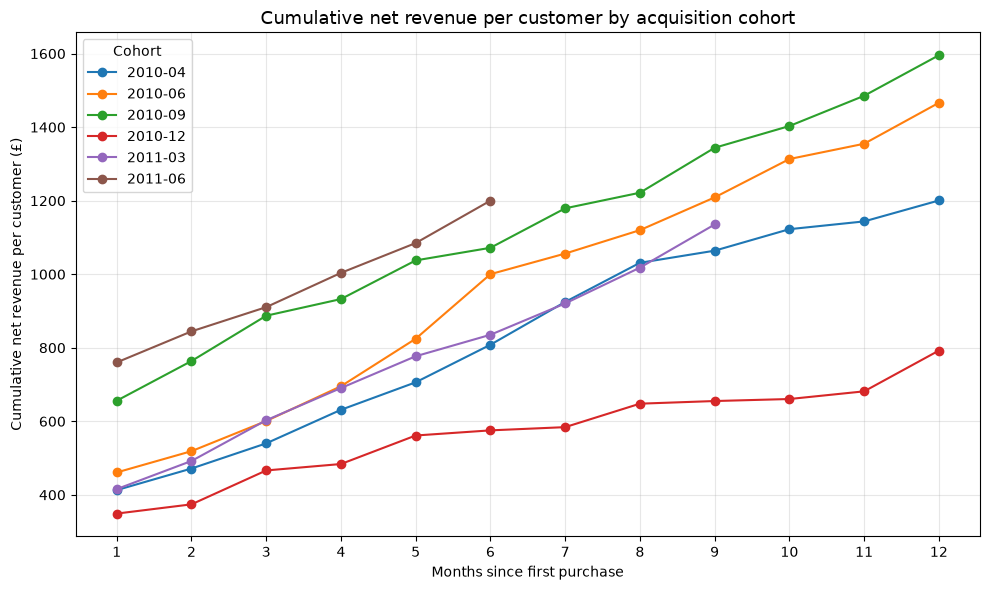

In [33]:
selected = ["2010-04", "2010-06", "2010-09", "2010-12", "2011-03", "2011-06"]

fig, ax = plt.subplots(figsize=(10, 6))
for c in selected:
    series = cum_ltv.loc[pd.Period(c, freq="M"), 0:11].dropna()
    ax.plot(series.index + 1, series.values, marker="o", label=c)

ax.set_title("Cumulative net revenue per customer by acquisition cohort", fontsize=13)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Cumulative net revenue per customer (£)")
ax.set_xticks(range(1, 13))
ax.legend(title="Cohort")
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("../images/ltv_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**What the LTV analysis shows**

- **Cancellations would have overstated revenue by £531K (3.2%).** It's small overall but concentrated in a few customers, as customer 12346 showed.
- **The first month is only a fraction of a customer's value.** For the April–December 2010 cohorts, first-month revenue is roughly 30–50% of 12-month revenue, so 12-month LTV is 2–3 times the first month.
- **Holiday cohorts are worth the least.** 12-month LTV falls through the autumn: October 2010 £1,019, November £913, December £792. The December 2010 curve (red) flattens from month 6 to month 11, meaning most of those customers stopped buying.
- **September 2010 is the strongest 2010 cohort** (£1,596 at 12 months). One plausible explanation is that September buyers are wholesalers stocking up for Christmas, while December buyers are smaller last-minute shoppers. The data can't confirm who the buyers are, so this is a hypothesis.
- **Mid-2011 cohorts are tracking somewhat ahead of the same months in 2010.** June 2011 reached £1,200 by month 6 against £1,000 for June 2010, a fair comparison because both pass through the same months of the year. Other same-month pairs are mixed, and the window is too short to call it a trend.

**Caveat:** The data-start problem extends past December 2009. A long-time customer who didn't order in December 2009 appears as "new" in January–March 2010, which inflates those cohorts' LTV (£1,643–£2,027 at 12 months). Comparisons therefore start from April 2010.

## 6. Findings and recommendations

**Key findings**
1. **Revenue is concentrated.** 34% of customers (Champions and Loyal) generate 80% of net revenue.
2. **Holiday-acquired customers are the least valuable.** The December 2010 cohort had the weakest retention and the lowest 12-month LTV (£792) of any full-year cohort. Retention, RFM, and LTV all point the same way.
3. **Seasonality drives behavior across all cohorts.** Every cohort reactivates in October-November, whatever its age.
4. **First-month revenue understates customer value by 2-3x.**

**Recommendations**
1. **Protect Champions and Loyal.** Retention and loyalty spend belongs here.
2. **Win back "Can't Lose Them" personally.** 72 high-value lapsed accounts is a small enough list for sales calls or account reviews rather than an email campaign.
3. **Nurture Potential Loyalists** toward a second and third order. This is the main growth lever.
4. **Judge acquisition on 6- or 12-month LTV, not first-order revenue.** Payback windows and allowable cost per acquisition set on first-month revenue would undervalue customers by 2-3x.
5. **Be careful with holiday acquisition spend.** Customers acquired in December are worth less. If holiday campaigns are judged on immediate revenue, they'll look better than they are over time.
6. **Deprioritize Hibernating customers.** A quarter of the customer base for 4% of revenue warrants low-cost automated reactivation at most.

**Limitations**
- Two years of data, starting mid-relationship for many customers. Early cohorts are inflated, and only one full holiday-to-holiday cycle is observed.
- 23% of transactions have no Customer ID and are excluded (13.6% of revenue).
- No marketing or channel data, so the analysis can't show *why* holiday customers are weaker, only that they are.
- LTV is historical, not predicted. A predictive model (such as BG/NBD) would be a natural next step.